In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import pytensor.tensor as pt
import arviz as az
import matplotlib.patches as mpatches
from sklearn.mixture import GaussianMixture
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KernelDensity
from sklearn.preprocessing import StandardScaler

In [29]:
ru_GT = 0.15
xu_GT = 0.2

In [30]:
def calculate_posterior(file):
    data = np.genfromtxt(file, delimiter=',', skip_header=1)
    t = data[:, -1]
    dt = np.diff(t).mean()
    F = data[:, :-1].T
    F[F<0] = 0
    events = np.isnan(F).argmax(axis=1)
    events[events==0] = t.shape[0]
    events -= 1
    F_proc = []
    e_proc = []
    
    for f in F:
        for i in range(len(f)):
            if f[i]<0:
                continue
            F_proc.append(f[i])
            if i+1==len(f)or np.isnan(f[i+1]):
                e_proc.append(1)
                break
            else:
                e_proc.append(0)
    
    
    RANDOM_SEED = 1234
    rng = np.random.default_rng(RANDOM_SEED)
    data = rng.standard_normal(10) + 1
    kT = 4.112
    with pm.Model() as model:
        F  = pm.Uniform("F", -100, 100, observed=F_proc)
        ru = pm.Uniform("ru", 0, 10)
        xu = pm.Uniform("xu", 0, 10)
        unbinding_rate = ru * np.exp(F * xu / kT)
        cap = unbinding_rate < 1
        unbinding_rate = unbinding_rate * cap + (1-cap)
        unbinding_event = pm.Bernoulli("unbinding", p = dt*unbinding_rate, observed=e_proc)
        pm.Deterministic("p", unbinding_rate)
    
    with model:
        idata = pm.sample(1000, chains=4)
    
    ru_samples = idata.posterior['ru'].data.flatten()
    xu_samples = idata.posterior['xu'].data.flatten()
    X = np.stack([ru_samples, xu_samples]).T
    
    pipe = Pipeline([('scaler', StandardScaler()), ('kde', KernelDensity(kernel='linear', bandwidth=0.4))])
    pipe.fit(X[:,:500])
    return pipe

In [31]:
file_80 = "stiff80_ru0.15_xu0.2_FT_curve_KP_19022024.csv"
file_40 = "stiff40_ru0.15_xu0.2_FT_curve_KP_19022024.csv"
file_20 = "stiff20_ru0.15_xu0.2_FT_curve_KP_19022024.csv"

post_80 = calculate_posterior(file_80)
post_40 = calculate_posterior(file_40)
post_20 = calculate_posterior(file_20)

Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [ru, xu]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 4 seconds.
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [ru, xu]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 4 seconds.
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [ru, xu]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 4 seconds.


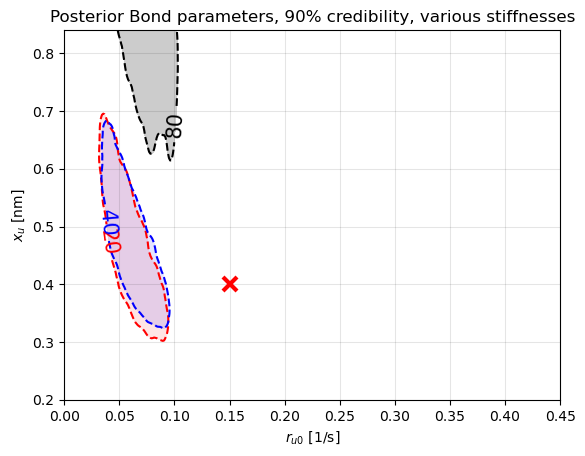

In [32]:
ru_GT = 0.15
xu_GT = 0.4
resolution = 200


ru_min = 0 * xu_GT
ru_max = 3 * ru_GT
xu_min = 0.5 * xu_GT
xu_max = 2.1 * xu_GT

offset = 0.001
resolution = 400

ru_ = np.linspace(ru_min, ru_max, resolution)
xu_ = np.linspace(xu_min, xu_max, resolution)
RU_, XU_ = np.meshgrid(ru_, xu_)
RU_ = RU_.flatten()
XU_ = XU_.flatten()
T_ = np.stack([RU_, XU_]).T



def draw_level(post_model, color='b', alpha=0.2, label='TODO'):
    logp = post_model.score_samples(T_)
    logpost_ = logp.reshape((resolution, resolution))
    
    logpost_ = logpost_.copy().reshape((resolution, -1))
    logpost_ -= np.nanmax(logpost_)
    draw = np.exp(logpost_)
    
    draw_flat = np.sort(draw.flatten())
    CDF = np.cumsum(draw_flat)
    CDF = CDF / CDF[-1]
    perc = 90
    idx = np.argmax(CDF > (100 - perc)/100)
    
    
    #plt.imshow(draw, origin='lower', cmap='ocean_r',
    #           extent=(ru_min, ru_max, xu_min, xu_max),
    #           aspect='auto',
    #           alpha=0.9)
    plt.contourf(draw, origin='lower', colors=[color],
                linestyles='--',
                extent=(ru_min, ru_max, xu_min, xu_max),
                levels=[draw_flat[idx], 1],
                alpha=alpha)
    cnt = plt.contour(draw, origin='lower', colors=[color],
                linestyles='--',
                extent=(ru_min, ru_max, xu_min, xu_max),
                levels=[draw_flat[idx]],
                alpha=1,
               )
    
    ax = plt.gca()
    ax.clabel(cnt, cnt.levels, inline=True, fmt=lambda _:label, fontsize=15)

draw_level(post_20, color='r', alpha=0.1, label='20')
draw_level(post_40, color='b', alpha=0.1, label='40')
draw_level(post_80, color='k', alpha=0.2, label='80')

plt.xlabel("$r_{u0}$ [1/s]")
plt.ylabel("$x_u$ [nm]")
plt.plot([ru_GT],[xu_GT], 'xr', ms=10, mew=3)
plt.gca().grid(c='k',alpha=0.1)

plt.xlim((ru_min, ru_max))
plt.ylim((xu_min, xu_max))

plt.title("Posterior Bond parameters, 90% credibility, various stiffnesses")
plt.savefig("posterior_stiffness.png", dpi=300)